In [33]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [ ]:
S = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

In [ ]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

In [ ]:
def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [ ]:
def black_scholes_greeks(S, K, T, r, sigma):

    d1,d2 = calculate_d1_d2(S, K, T, r, sigma)

    delta_c = norm.cdf(d1)
    delta_p = -(norm.cdf(-d1))

    gamma = norm.pdf(d1) / (S * sigma * np.sqrt(T))

    vega = S * norm.pdf(d1) * np.sqrt(T)

    theta_c = - (S * norm.pdf(d1) * sigma) / (2 * np.sqrt(T)) - r * K * np.exp(-r*T) * norm.cdf(d2)
    theta_p = - (S * norm.pdf(d1) * sigma) / (2 * np.sqrt(T)) + r * K * np.exp(-r*T) * norm.cdf(-d2)

    call_greeks = {
        "delta": delta_c,
        "gamma": gamma,
        "vega": vega,
        "theta": theta_c
        }

    put_greeks = {
        "delta": delta_p,
        "gamma": gamma,
        "vega": vega,
        "theta": theta_p
    }

    return call_greeks, put_greeks

In [ ]:
S, K, T, r, sigma = 100, 100, 1, 0.05, 0.20

h = 0.01
h_sigma = 0.0001
h_T = 0.0001

# Analytical Greeks
call_greeks, put_greeks = black_scholes_greeks(S, K, T, r, sigma)

# Base prices
C, P = black_scholes_price(S, K, T, r, sigma)

# Delta and Gamma
C_plus, P_plus = black_scholes_price(S + h, K, T, r, sigma)
C_minus, P_minus = black_scholes_price(S - h, K, T, r, sigma)

delta_c = (C_plus - C_minus) / (2 * h)
delta_p = (P_plus - P_minus) / (2 * h)

gamma_c = (C_plus - 2 * C + C_minus) / h ** 2
gamma_p = (P_plus - 2 * P + P_minus) / h ** 2

# Vega
C_plus_v, P_plus_v = black_scholes_price(S, K, T, r, sigma + h_sigma)
C_minus_v, P_minus_v = black_scholes_price(S, K, T, r, sigma - h_sigma)

vega_c = (C_plus_v - C_minus_v) / (2 * h_sigma)
vega_p = (P_plus_v - P_minus_v) / (2 * h_sigma)

# Theta (negative derivative with respect to time to expiry)
C_plus_t, P_plus_t = black_scholes_price(S, K, T + h_T, r, sigma)
C_minus_t, P_minus_t = black_scholes_price(S, K, T - h_T, r, sigma)

theta_c = -(C_plus_t - C_minus_t) / (2 * h_T)
theta_p = -(P_plus_t - P_minus_t) / (2 * h_T)

# Compare results
numerical_call = [delta_c, gamma_c, vega_c, theta_c]
numerical_put = [delta_p, gamma_p, vega_p, theta_p]

for option, analytical, numerical in [
    ("CALL", call_greeks, numerical_call),
    ("PUT", put_greeks, numerical_put)
]:
    print(f"\n{option} GREEKS")
    for greek, value in zip(["delta", "gamma", "vega", "theta"], numerical):
        print(f"{greek}: Analytical = {analytical[greek]:.6f}, Numerical = {value:.6f}")

In [ ]:
S = np.array([80, 90, 100, 110, 120])
K, T, r, sigma = 100, 1, 0.05, 0.20

call, put = black_scholes_price(S, K, T, r, sigma)
call_greeks, put_greeks = black_scholes_greeks(S, K, T, r, sigma)

print("Call prices:", call)
print("Put prices:", put)
print("Call deltas:", call_greeks["delta"])
print("Put deltas:", put_greeks["delta"])

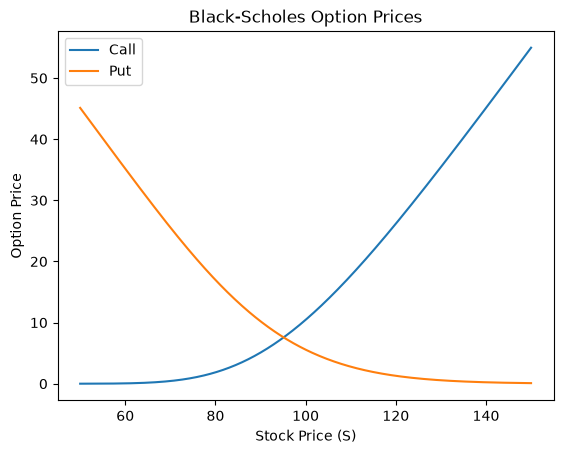

In [44]:
K, T, r, sigma = 100, 1, 0.05, 0.20
S = np.linspace(50, 150, 500)

call, put = black_scholes_price(S, K, T, r, sigma)

plt.plot(S, call, label = "Call")
plt.plot(S, put, label = "Put")

plt.xlabel("Stock Price (S)")
plt.ylabel("Option Price")
plt.title("Black-Scholes Option Prices")

plt.legend()

plt.show()

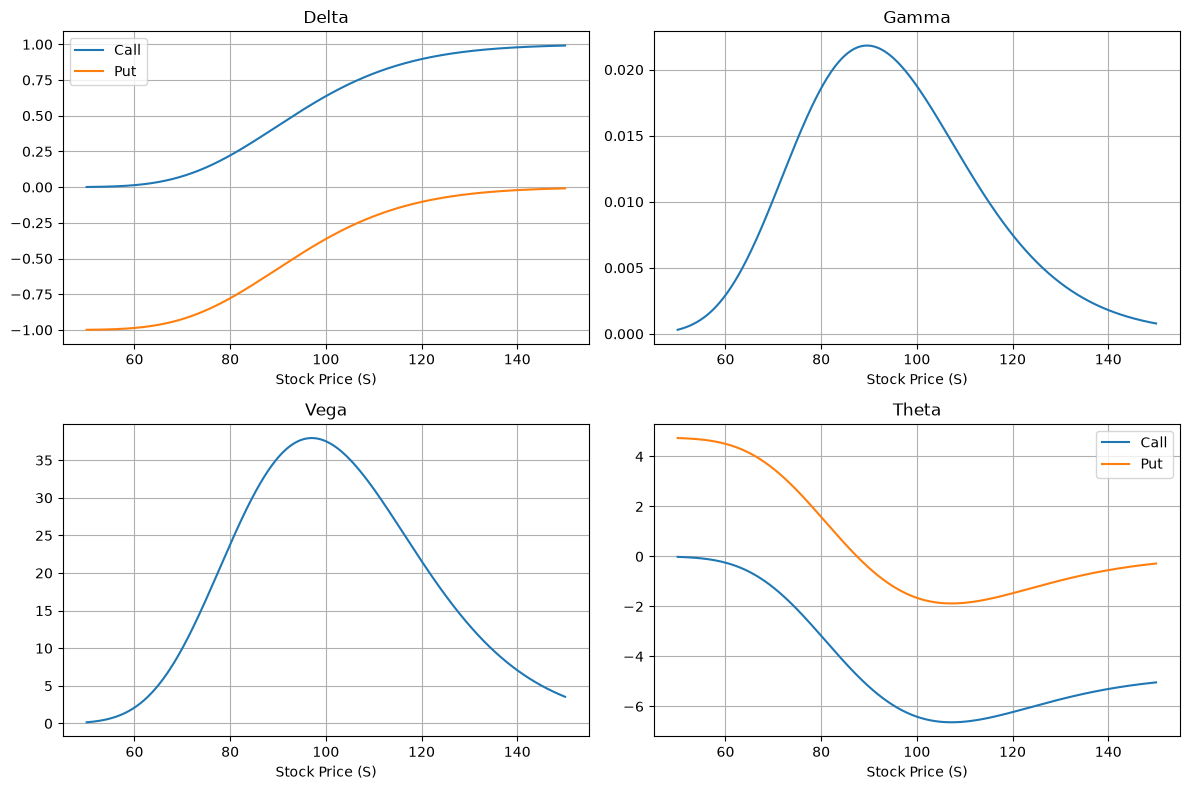

In [48]:
K, T, r, sigma = 100, 1, 0.05, 0.20
S = np.linspace(50, 150, 500)

call_greeks, put_greeks = black_scholes_greeks(S, K, T, r, sigma)

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Delta — top left
axs[0, 0].plot(S, call_greeks["delta"], label="Call")
axs[0, 0].plot(S, put_greeks["delta"], label="Put")
axs[0, 0].set_title("Delta")
axs[0, 0].legend()

# Gamma — top right
axs[0, 1].plot(S, call_greeks["gamma"])
axs[0, 1].set_title("Gamma")

# Vega — bottom left
axs[1, 0].plot(S, call_greeks["vega"])
axs[1, 0].set_title("Vega")

# Theta — bottom right
axs[1, 1].plot(S, call_greeks["theta"], label="Call")
axs[1, 1].plot(S, put_greeks["theta"], label="Put")
axs[1, 1].set_title("Theta")
axs[1, 1].legend()

# Labels and formatting
for ax in axs.flat:
    ax.set_xlabel("Stock Price (S)")
    ax.grid(True)

plt.tight_layout()
plt.show()


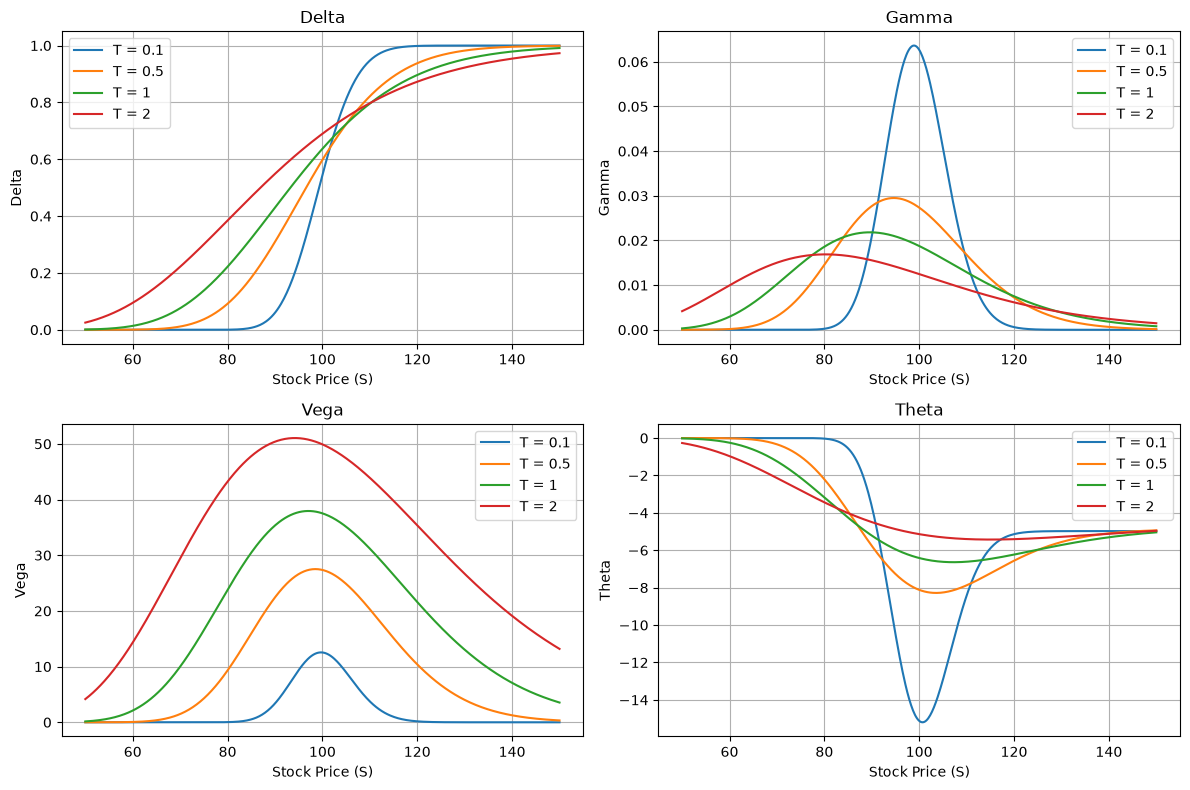

In [ ]:
S = np.linspace(50, 150, 500)
K, r, sigma = 100, 0.05, 0.20
maturities = [0.1, 0.5, 1, 2]

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

greeks = ["delta", "gamma", "vega", "theta"]

for T in maturities:

    call_greeks, put_greeks = black_scholes_greeks(S, K, T, r, sigma)

    for ax, greek in zip(axs.flat, greeks):
        ax.plot(S, call_greeks[greek], label=f"T = {T}")

for ax, greek in zip(axs.flat, greeks):
    ax.set_title(greek.capitalize())
    ax.set_xlabel("Stock Price (S)")
    ax.set_ylabel(greek.capitalize())
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
def binomial_price(S, K, u, d, R, n):

    q = (R - d)/(u - d)

    Sn_list = []

    for k in range(n+1):
        Sn = u**k * d**(n-k) * S
        Sn_list.append(Sn)

    Cn_list = []

    for i in range(len(Sn_list)):
        Cn = max(Sn_list[i] - K, 0)
        Cn_list.append(Cn)

    current_values = Cn_list

    for k in range(1,n + 1):

        previous_values = []
        
        for i in range(len(Cn_list) - k):
            x = 1/R * (q * (current_values[i+1]) + (1-q) * (current_values[i]))
            previous_values.append(x)

        current_values = previous_values

    return current_values[0]

In [69]:
S, K, T, r, sigma = 100, 100, 1, 0.05, 0.20
n_values = [100, 200, 400, 800, 1200, 1600, 2000, 2400, 2800, 3200, 3600, 4000]

prices = []

for n in n_values:

    delta_t = T/n

    u = np.exp(sigma * np.sqrt(delta_t))
    d = np.exp(-sigma * np.sqrt(delta_t))
    R = np.exp(r * delta_t)

    price = binomial_price(S, K, u, d, R, n)
    prices.append(price)

Text(0, 0.5, 'Absolute Error')

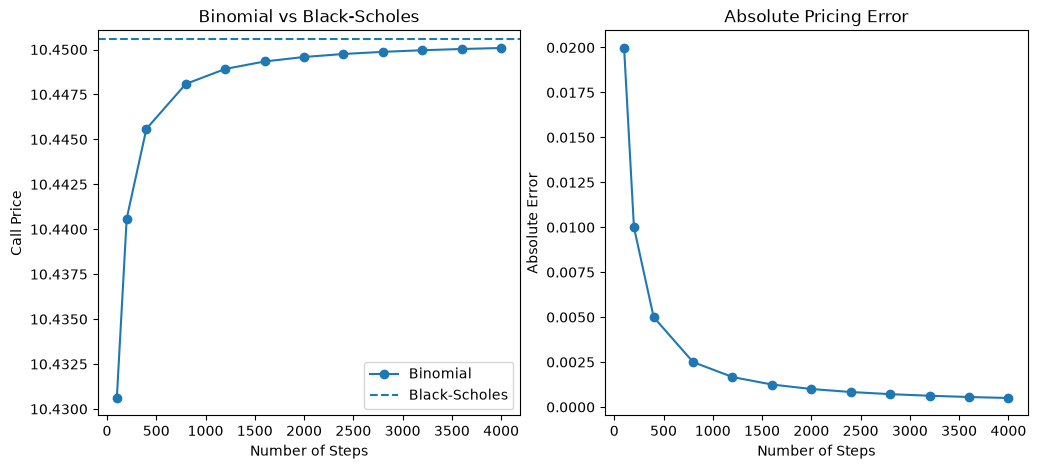

In [70]:
C_BS, _ = black_scholes_price(S, K, T, r, sigma)

errors = np.abs(np.array(prices) - C_BS)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Price convergence
axs[0].plot(n_values, prices, marker="o", label="Binomial")
axs[0].axhline(C_BS, linestyle="--", label="Black-Scholes")
axs[0].set_title("Binomial vs Black-Scholes")
axs[0].set_xlabel("Number of Steps")
axs[0].set_ylabel("Call Price")
axs[0].legend()


# Absolute error
axs[1].plot(n_values, errors, marker="o")
axs[1].set_title("Absolute Pricing Error")
axs[1].set_xlabel("Number of Steps")
axs[1].set_ylabel("Absolute Error")